# 90 · Análise dos resultados

Junta todos os resultados salvos em `resultados/` e gera as tabelas e as figuras do artigo (salvas em `figuras/`).

**Regras da análise**
- Das redes, entram só as execuções com o learning rate escolhido pela validação.
- Na comparação final, cada modelo usa a **janela com o menor erro médio de validação** (média das 3 seeds). A janela nunca é escolhida pelo teste.
- O ganho é medido em relação ao **naive** e ao **melhor baseline no teste**. Escolher o baseline pelo teste favorece o baseline, então a comparação é conservadora.
- Os valores são média ± desvio padrão das 3 seeds.

In [1]:
# Configuração: igual em todos os notebooks
import os, sys
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJETO = '/content/drive/MyDrive/RN-Projeto'
except ImportError:          # fora do Colab (ex.: rodando no computador)
    PROJETO = os.path.abspath('.')
sys.path.insert(0, os.path.join(PROJETO, 'src'))
print('Pasta do projeto:', PROJETO)

import importlib
import rn_utils as ru
importlib.reload(ru)        # pega a versão mais nova se o 02 foi rodado de novo
ru.configurar(PROJETO)

Mounted at /content/drive
Pasta do projeto: /content/drive/MyDrive/RN-Projeto
Projeto: /content/drive/MyDrive/RN-Projeto | dispositivo: cpu


In [2]:
import io, json, glob, contextlib, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter, NullFormatter
from scipy import stats

pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
FIG = os.path.join(PROJETO, 'figuras')
os.makedirs(FIG, exist_ok=True)

def salvar(nome):
    plt.savefig(os.path.join(FIG, nome), dpi=200, bbox_inches='tight')

def marcas_de_razao(lo, hi):
    candidatas = (.8, .9, 1, 1.25, 1.5, 2, 3) if hi / lo < 4 else (.5, 1, 2, 5, 10, 20, 50)
    return [v for v in candidatas if lo <= v <= hi]

df = ru.carregar_resultados()
redes, baselines = df[df.tipo == 'rede'].copy(), df[df.tipo == 'baseline'].copy()
TODOS = ['DLinear', 'LSTM', 'TCN', 'Informer', 'PatchTST']
ORDEM = [m for m in TODOS if m in set(redes.modelo)]
BASES = [d for d in ru.DATASETS if d in set(df.dataset)]
CORES = dict(zip(TODOS, ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3']))
PERT = list(ru.PERTURBACOES)
CURTO = {p: p.replace('embaralhar_', '') for p in PERT}
UNIDADE = {'ETTh1': 'temperatura do óleo (°C)', 'Weather': 'CO₂ (ppm)'}

esperado = {ds: len(c['lookbacks']) * len(c['seeds']) for ds, c in ru.DATASETS.items()}
contagem = redes.pivot_table(index='modelo', columns='dataset', values='L', aggfunc='size').reindex(ORDEM)
print('Execuções esperadas por modelo (janelas × seeds):', esperado)
contagem

Execuções esperadas por modelo (janelas × seeds): {'ETTh1': 15, 'Weather': 9}


dataset,ETTh1,Weather
modelo,,
DLinear,15,9
LSTM,15,9
TCN,15,9
Informer,15,9
PatchTST,15,9


## 1. Escolha da janela de cada modelo

Para cada modelo, a janela usada na comparação é a de **menor erro médio de validação**. A tabela também mostra a janela que teria o menor erro de **teste**, só para transparência. Quando as duas diferem, o modelo se comporta de forma diferente nos dois períodos, e usar a janela do teste seria escolher o resultado depois de vê-lo.

In [3]:
agg = (redes.groupby(['dataset', 'modelo', 'L'])
       .agg(val=('mse_val', 'mean'), mse=('original_mse', 'mean'), mse_dp=('original_mse', 'std'),
            mae=('original_mae', 'mean'), mae_dp=('original_mae', 'std'), mse_ss=('original_mse_ss', 'mean'),
            n=('seed', 'size'), parametros=('n_parametros', 'first'), tempo_s=('tempo_treino_s', 'mean'),
            epocas=('epocas_rodadas', 'mean'), **{p: (f'{p}_razao', 'mean') for p in PERT})
       .reset_index())
ESCOLHA = agg.loc[agg.groupby(['dataset', 'modelo'])['val'].idxmin()].set_index(['dataset', 'modelo'])
L_TESTE = agg.loc[agg.groupby(['dataset', 'modelo'])['mse'].idxmin()].set_index(['dataset', 'modelo'])['L']

for ds in BASES:
    a = agg[agg.dataset == ds]
    janelas = pd.DataFrame({'janela escolhida (validação)': ESCOLHA.loc[ds, 'L'],
                            'janela de menor erro no teste': L_TESTE.loc[ds]}).reindex(ORDEM)
    erros = pd.concat({'MSE de validação': a.pivot(index='modelo', columns='L', values='val').reindex(ORDEM),
                       'MSE de teste': a.pivot(index='modelo', columns='L', values='mse').reindex(ORDEM)}, axis=1)
    print(f'===== {ds}')
    display(janelas)
    display(erros.style.format('{:.4f}', na_rep='—')
            .highlight_min(axis=1, subset=pd.IndexSlice[:, pd.IndexSlice['MSE de validação', :]],
                           props='font-weight:bold; background-color:#d9ead3')
            .highlight_min(axis=1, subset=pd.IndexSlice[:, pd.IndexSlice['MSE de teste', :]],
                           props='font-weight:bold; background-color:#fce5cd'))

===== ETTh1


,janela escolhida (validação),janela de menor erro no teste
modelo,,
DLinear,512,336
LSTM,336,720
TCN,192,512
Informer,336,96
PatchTST,192,192


===== Weather


,janela escolhida (validação),janela de menor erro no teste
modelo,,
DLinear,720,720
LSTM,336,720
TCN,336,720
Informer,96,720
PatchTST,336,720


## 2. Tabela principal

Cada modelo aparece na janela escolhida pela validação. Os baselines aparecem com o próprio erro: o `naive` e o `sazonal` não dependem da janela, e a `media_janela` aparece na janela em que foi melhor.

- **ganho** = 1 − MSE do modelo / MSE de referência. Positivo significa que o modelo erra menos que a referência.
- **MSE sem dias suspeitos**: exclui as amostras de teste cujo alvo toca os dias constantes do ETTh1. No Weather é igual ao MSE.

In [4]:
REF, linhas = {}, []
for ds in BASES:
    b = baselines[baselines.dataset == ds]
    melhor = b.loc[b['original_mse'].idxmin()]
    naive = float(b[b.modelo == 'naive']['original_mse'].iloc[0])
    REF[ds] = {'nome': melhor.modelo + (f' (L={int(melhor.L)})' if melhor.modelo == 'media_janela' else ''),
               'modelo': melhor.modelo, 'L': int(melhor.L), 'mse': float(melhor['original_mse']), 'naive': naive}
    for mod in ORDEM:
        if (ds, mod) not in ESCOLHA.index:
            continue
        e = ESCOLHA.loc[(ds, mod)]
        linhas.append({'base': ds, 'modelo': mod, 'L': int(e.L), 'MSE': e.mse, 'dp MSE': e.mse_dp,
                       'MAE': e.mae, 'dp MAE': e.mae_dp, 'MSE sem dias suspeitos': e.mse_ss,
                       'ganho sobre o naive': 1 - e.mse / naive, 'ganho sobre o melhor baseline': 1 - e.mse / REF[ds]['mse'],
                       'parâmetros': int(e.parametros), 'épocas (média)': e.epocas})
    for _, r in b.sort_values('original_mse').groupby('modelo', sort=False).head(1).iterrows():
        linhas.append({'base': ds, 'modelo': f'{r.modelo} (baseline)',
                       'L': int(r.L) if r.modelo == 'media_janela' else np.nan,
                       'MSE': r['original_mse'], 'MAE': r['original_mae'], 'MSE sem dias suspeitos': r['original_mse_ss'],
                       'ganho sobre o naive': 1 - r['original_mse'] / naive,
                       'ganho sobre o melhor baseline': 1 - r['original_mse'] / REF[ds]['mse']})
TAB = pd.DataFrame(linhas).set_index(['base', 'modelo'])
TAB.to_csv(os.path.join(FIG, 'tabela_principal.csv'))

FORMATO = {'L': '{:.0f}', 'MSE': '{:.4f}', 'dp MSE': '{:.4f}', 'MAE': '{:.4f}', 'dp MAE': '{:.4f}',
           'MSE sem dias suspeitos': '{:.4f}', 'ganho sobre o naive': '{:+.1%}',
           'ganho sobre o melhor baseline': '{:+.1%}', 'parâmetros': '{:,.0f}', 'épocas (média)': '{:.1f}'}
for ds in BASES:
    print(f"===== {ds}: melhor baseline no teste = {REF[ds]['nome']} (MSE {REF[ds]['mse']:.4f}) | naive: MSE {REF[ds]['naive']:.4f}")
    display(TAB.loc[ds].style.format(FORMATO, na_rep='—')
            .background_gradient(subset=['MSE'], cmap='RdYlGn_r')
            .bar(subset=['ganho sobre o melhor baseline'], align='zero', color=['#e06666', '#93c47d']))

===== ETTh1: melhor baseline no teste = media_janela (L=96) (MSE 0.0667) | naive: MSE 0.0693


,L,MSE,dp MSE,MAE,dp MAE,MSE sem dias suspeitos,ganho sobre o naive,ganho sobre o melhor baseline,parâmetros,épocas (média)
modelo,,,,,,,,,,
DLinear,512,0.0568,0.0022,0.1849,0.0035,0.0592,+17.9%,+14.8%,"98,496",9.0
LSTM,336,0.0546,0.0014,0.1798,0.0017,0.0562,+21.2%,+18.2%,"211,552",18.0
TCN,192,0.0547,0.0004,0.1792,0.0010,0.0561,+21.0%,+17.9%,"143,264",9.7
Informer,336,0.0688,0.0055,0.2059,0.0067,0.0717,+0.7%,-3.1%,"11,302,401",6.0
PatchTST,192,0.0541,0.0007,0.1767,0.0010,0.0556,+21.9%,+18.9%,"53,792",24.0
media_janela (baseline),96,0.0667,—,0.1985,—,0.0659,+3.7%,+0.0%,—,—
naive (baseline),—,0.0693,—,0.2033,—,0.0678,+0.0%,-3.8%,—,—
sazonal (baseline),—,0.0714,—,0.2105,—,0.0704,-3.2%,-7.1%,—,—


===== Weather: melhor baseline no teste = media_janela (L=336) (MSE 0.5327) | naive: MSE 0.5550


,L,MSE,dp MSE,MAE,dp MAE,MSE sem dias suspeitos,ganho sobre o naive,ganho sobre o melhor baseline,parâmetros,épocas (média)
modelo,,,,,,,,,,
DLinear,720,0.4024,0.0016,0.4448,0.0013,0.4024,+27.5%,+24.5%,"138,432",18.3
LSTM,336,0.5563,0.0314,0.5121,0.0077,0.5563,-0.2%,-4.4%,"211,552",11.7
TCN,336,0.4152,0.0147,0.4465,0.0078,0.4152,+25.2%,+22.1%,"168,096",19.0
Informer,96,0.4951,0.0141,0.4869,0.0088,0.4951,+10.8%,+7.1%,"11,302,401",8.3
PatchTST,336,0.5532,0.0207,0.5037,0.0056,0.5532,+0.3%,-3.9%,"921,184",14.0
media_janela (baseline),336,0.5327,—,0.5465,—,0.5327,+4.0%,+0.0%,—,—
naive (baseline),—,0.5550,—,0.5246,—,0.5550,+0.0%,-4.2%,—,—
sazonal (baseline),—,0.7282,—,0.6091,—,0.7282,-31.2%,-36.7%,—,—


## 3. Panorama: erro de teste por modelo e janela

Cada célula é o MSE de teste médio das 3 seeds. O contorno marca a janela escolhida pela validação. Cores mais verdes indicam erro menor dentro de cada base.

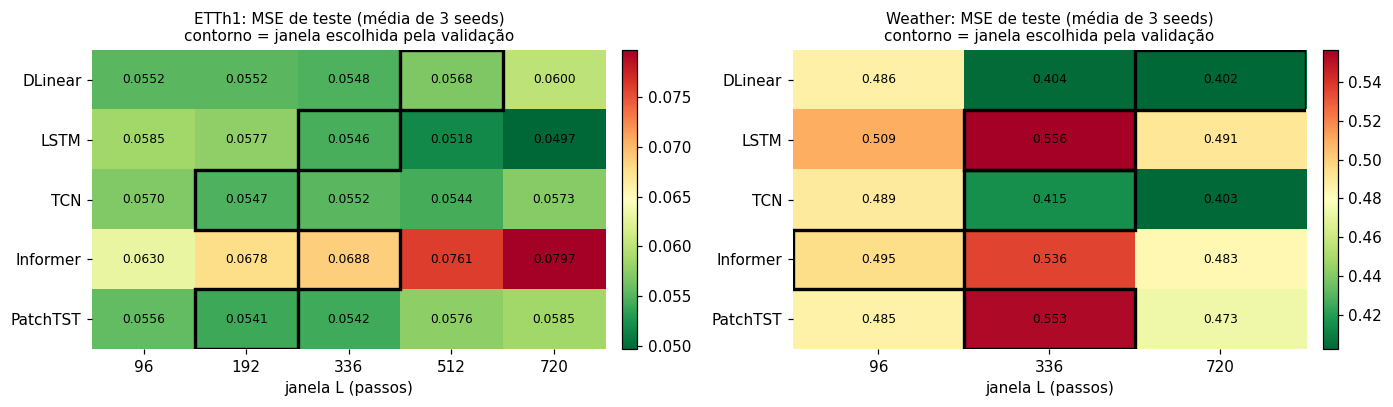

In [5]:
fig, axs = plt.subplots(1, len(BASES), figsize=(6.4 * len(BASES), 3.8), squeeze=False)
for ax, ds in zip(axs[0], BASES):
    tes = agg[agg.dataset == ds].pivot(index='modelo', columns='L', values='mse').reindex(ORDEM)
    im = ax.imshow(tes.values, cmap='RdYlGn_r', aspect='auto')
    ax.set_xticks(range(tes.shape[1]), tes.columns)
    ax.set_yticks(range(len(ORDEM)), ORDEM)
    for i, mod in enumerate(ORDEM):
        for j in range(tes.shape[1]):
            v = tes.iloc[i, j]
            if np.isfinite(v):
                ax.text(j, i, f'{v:.4f}' if ds == 'ETTh1' else f'{v:.3f}', ha='center', va='center', fontsize=8)
        if (ds, mod) in ESCOLHA.index:
            j = list(tes.columns).index(ESCOLHA.loc[(ds, mod), 'L'])
            ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, lw=2.2, ec='black'))
    ax.spines[:].set_visible(False)
    ax.set_xlabel('janela L (passos)')
    ax.set_title(f'{ds}: MSE de teste (média de 3 seeds)\ncontorno = janela escolhida pela validação', fontsize=10)
    fig.colorbar(im, ax=ax, fraction=.046, pad=.03)
plt.tight_layout(); salvar('fig1_panorama_mse.png'); plt.show()

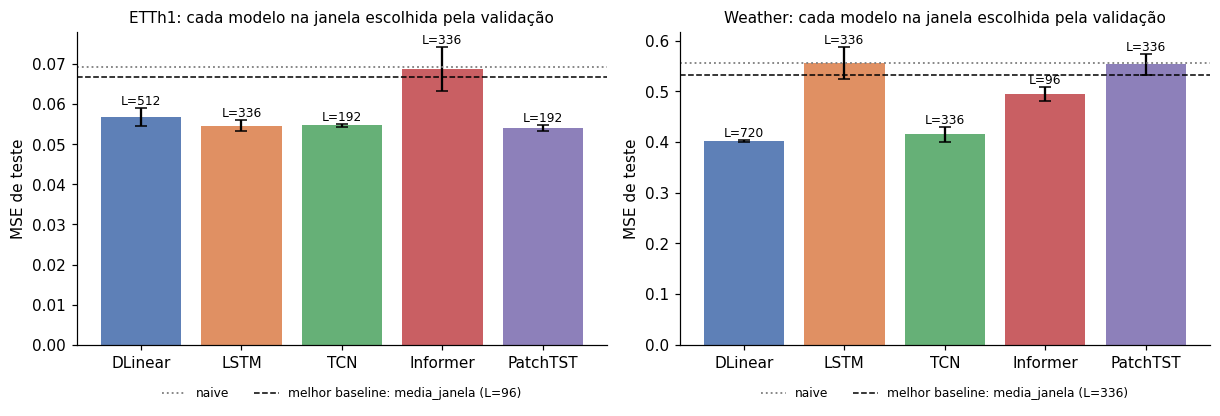

In [6]:
fig, axs = plt.subplots(1, len(BASES), figsize=(5.6 * len(BASES), 3.9), squeeze=False)
for ax, ds in zip(axs[0], BASES):
    t = TAB.loc[ds].loc[[m for m in ORDEM if m in TAB.loc[ds].index]]
    x = np.arange(len(t))
    ax.bar(x, t['MSE'], yerr=t['dp MSE'].fillna(0), capsize=4, color=[CORES[m] for m in t.index], alpha=.9)
    for xi, (_, r) in zip(x, t.iterrows()):
        ax.text(xi, r['MSE'] + (0 if np.isnan(r['dp MSE']) else r['dp MSE']), f"L={r['L']:.0f}",
                ha='center', va='bottom', fontsize=8)
    ax.axhline(REF[ds]['naive'], color='gray', ls=':', lw=1.2, label='naive')
    ax.axhline(REF[ds]['mse'], color='black', ls='--', lw=1, label=f"melhor baseline: {REF[ds]['nome']}")
    ax.set_xticks(x, t.index)
    ax.set_ylabel('MSE de teste')
    ax.set_title(f'{ds}: cada modelo na janela escolhida pela validação', fontsize=10)
    ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.1), ncol=2, frameon=False)
plt.tight_layout(); salvar('fig2_mse_por_modelo.png'); plt.show()

## 4. Erro em função do tamanho da janela

Se a curva desce com L, o modelo aproveita o passado distante. Se fica plana ou sobe, ele o ignora ou é prejudicado por ele. As barras são ± 1 desvio padrão entre seeds, e as linhas cinzas são os baselines.

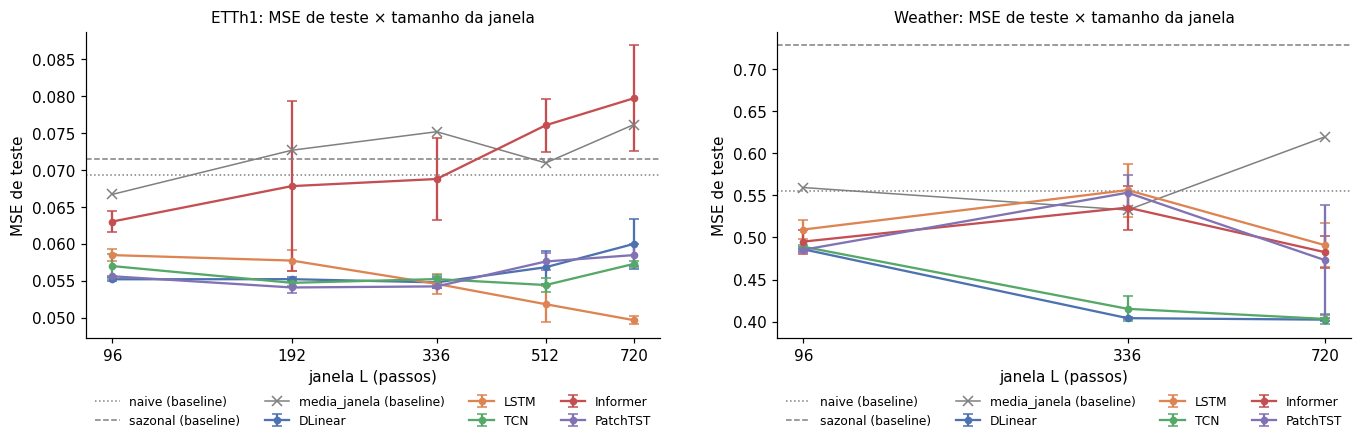

In [7]:
fig, axs = plt.subplots(1, len(BASES), figsize=(6.4 * len(BASES), 4.2), squeeze=False)
for ax, ds in zip(axs[0], BASES):
    a = agg[agg.dataset == ds]
    for mod in ORDEM:
        s = a[a.modelo == mod].sort_values('L')
        ax.errorbar(s.L, s.mse, yerr=s.mse_dp.fillna(0), marker='o', ms=4, capsize=3, color=CORES[mod], label=mod)
    b = baselines[baselines.dataset == ds]
    for nome, ls in (('naive', ':'), ('sazonal', '--')):
        ax.axhline(b[b.modelo == nome]['original_mse'].iloc[0], color='gray', ls=ls, lw=1, label=f'{nome} (baseline)')
    mj = b[b.modelo == 'media_janela'].sort_values('L')
    ax.plot(mj.L, mj['original_mse'], color='gray', lw=1, marker='x', label='media_janela (baseline)')
    Ls = ru.DATASETS[ds]['lookbacks']
    ax.set_xscale('log', base=2); ax.set_xticks(Ls, Ls); ax.minorticks_off()
    ax.set_xlabel('janela L (passos)'); ax.set_ylabel('MSE de teste')
    ax.set_title(f'{ds}: MSE de teste × tamanho da janela', fontsize=10)
    ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.15), ncol=4, frameon=False)
plt.tight_layout(); salvar('fig3_mse_por_janela.png'); plt.show()

## 5. Dependência da ordem: testes de embaralhamento

Razão = MSE com a janela embaralhada / MSE original, média de 3 permutações e 3 seeds. **×1,0 significa que o modelo ignora aquela ordem.** A escala de cor é logarítmica, e o azul indica razão abaixo de 1: o erro diminui com o embaralhamento.

| Teste | Pergunta |
|---|---|
| `tudo` | o modelo usa a ordem da janela? |
| `antigo` | usa a ordem do passado distante (os 75% mais antigos)? |
| `recente` | usa a ordem dos 25% mais recentes? |
| `blocos` | usa a ordem global, além da ordem local dentro de blocos de 16 passos? |

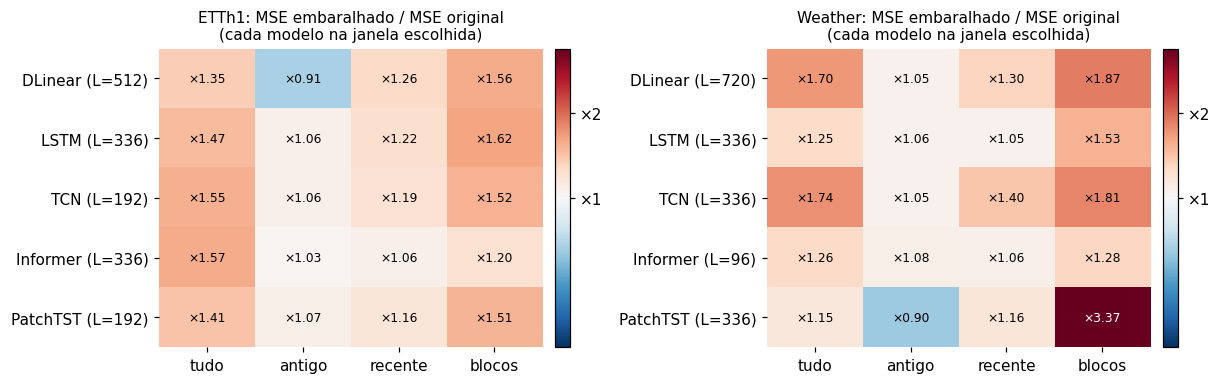

In [8]:
razoes = ESCOLHA[PERT].astype(float)
lim = max(float(np.log10(razoes.to_numpy()).max()), .3)
fig, axs = plt.subplots(1, len(BASES), figsize=(5.6 * len(BASES), 3.6), squeeze=False)
for ax, ds in zip(axs[0], BASES):
    r = razoes.loc[ds].reindex(ORDEM)
    im = ax.imshow(np.log10(r.values), cmap='RdBu_r', norm=TwoSlopeNorm(0, vmin=-lim / 4, vmax=lim), aspect='auto')
    ax.set_xticks(range(len(PERT)), [CURTO[p] for p in PERT])
    ax.set_yticks(range(len(ORDEM)), [f'{m} (L={int(ESCOLHA.loc[(ds, m), "L"])})' for m in ORDEM])
    for i in range(r.shape[0]):
        for j in range(r.shape[1]):
            v = r.iloc[i, j]
            ax.text(j, i, f'×{v:.2f}', ha='center', va='center', fontsize=8, color='white' if np.log10(v) > lim * .6 else 'black')
    ax.spines[:].set_visible(False)
    ax.set_title(f'{ds}: MSE embaralhado / MSE original\n(cada modelo na janela escolhida)', fontsize=10)
    marcas = marcas_de_razao(10 ** (-lim / 4), 10 ** lim)
    cb = fig.colorbar(im, ax=ax, fraction=.046, pad=.03, ticks=np.log10(marcas))
    cb.ax.set_yticklabels([f'×{v:g}' for v in marcas])
plt.tight_layout(); salvar('fig4_embaralhamento.png'); plt.show()

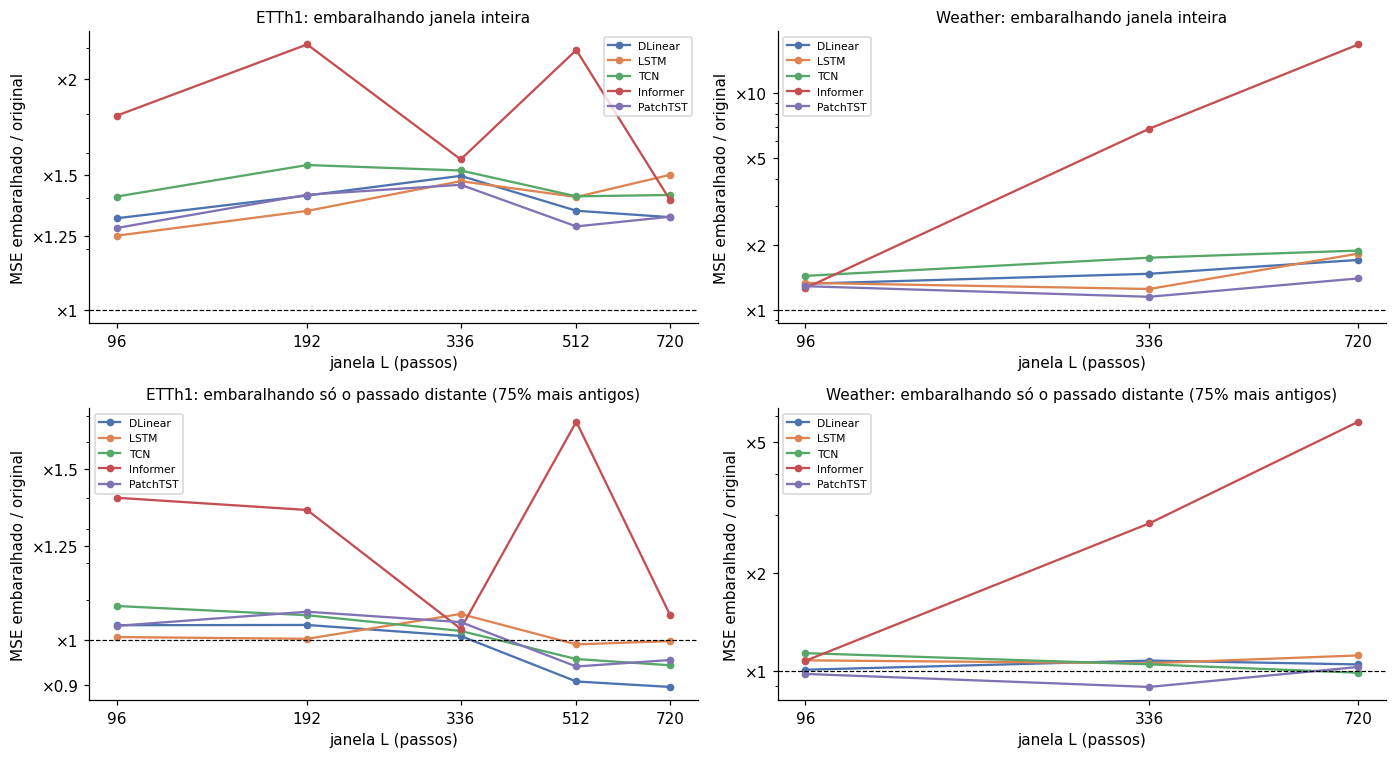

In [9]:
fig, axs = plt.subplots(2, len(BASES), figsize=(6.4 * len(BASES), 7), squeeze=False)
for col, ds in enumerate(BASES):
    a = agg[agg.dataset == ds]
    for lin, (p, titulo) in enumerate((('embaralhar_tudo', 'janela inteira'), ('embaralhar_antigo', 'só o passado distante (75% mais antigos)'))):
        ax = axs[lin, col]
        for mod in ORDEM:
            s = a[a.modelo == mod].sort_values('L')
            ax.plot(s.L, s[p], marker='o', ms=4, color=CORES[mod], label=mod)
        ax.axhline(1, color='black', lw=.8, ls='--')
        Ls = ru.DATASETS[ds]['lookbacks']
        ax.set_xscale('log', base=2); ax.set_xticks(Ls, Ls); ax.minorticks_off()
        ax.set_yscale('log')
        ax.set_yticks(marcas_de_razao(*ax.get_ylim()))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'×{v:g}'))
        ax.yaxis.set_minor_formatter(NullFormatter())
        ax.set_xlabel('janela L (passos)'); ax.set_ylabel('MSE embaralhado / original')
        ax.set_title(f'{ds}: embaralhando {titulo}', fontsize=10)
        ax.legend(fontsize=7)
plt.tight_layout(); salvar('fig5_embaralhamento_por_janela.png'); plt.show()

## 6. As diferenças entre modelos são estatisticamente significativas?

Teste de **Diebold–Mariano** sobre o erro de cada amostra de teste (MSE nos 96 passos, média das 3 seeds), com cada modelo na sua janela escolhida. Todas as janelas preveem exatamente os mesmos alvos, então a comparação é pareada amostra a amostra.

- Previsões vizinhas compartilham 95 dos 96 passos, então os erros são autocorrelacionados. A variância usa o estimador de **Newey–West com defasagem H − 1 = 95**. Um teste comum, que supõe amostras independentes, exageraria a significância.
- São várias comparações por base, então os p-valores são corrigidos por **Holm**.
- O teste avalia a diferença de acurácia **no período de teste**. A variação entre seeds aparece no desvio padrão da tabela principal.

In [10]:
def erros_por_amostra(ds, modelo, nome_arquivo):
    z = np.load(os.path.join(PROJETO, 'resultados', ds, modelo, nome_arquivo + '.npz'))
    return z['t'], z['original_mse']

def erro_do_modelo(ds, mod):
    e = ESCOLHA.loc[(ds, mod)]
    g = redes[(redes.dataset == ds) & (redes.modelo == mod) & (redes.L == e.L)]
    ts, es = zip(*(erros_por_amostra(ds, mod, ru.id_execucao(ds, mod, int(e.L), r.lr, int(r.seed))) for r in g.itertuples()))
    assert all(np.array_equal(t, ts[0]) for t in ts), 'amostras diferentes entre seeds'
    return ts[0], np.mean(es, axis=0)

def diebold_mariano(e1, e2, h):
    """Estatística DM com variância de longo prazo de Newey–West (pesos de Bartlett, defasagem h − 1)."""
    d = np.asarray(e1, float) - np.asarray(e2, float)
    n, dc = len(d), d - d.mean()
    lrv = dc @ dc / n + 2 * sum((1 - k / h) * (dc[k:] @ dc[:-k]) / n for k in range(1, h))
    est = d.mean() / np.sqrt(lrv / n)
    return d.mean(), est, 2 * stats.t.sf(abs(est), df=n - 1)

def holm(p):
    p = np.asarray(p, float); ajust = np.empty_like(p); acum = 0.0
    for k, i in enumerate(np.argsort(p)):
        acum = max(acum, (len(p) - k) * p[i]); ajust[i] = min(acum, 1.0)
    return ajust

DM = []
for ds in BASES:
    erros = {mod: erro_do_modelo(ds, mod) for mod in ORDEM if (ds, mod) in ESCOLHA.index}
    ref = REF[ds]
    erros['melhor baseline'] = erros_por_amostra(ds, ref['modelo'], f"{ds}_{ref['modelo']}_L{ref['L']}_H{ru.HORIZONTE}")
    t0 = next(iter(erros.values()))[0]
    assert all(np.array_equal(t, t0) for t, _ in erros.values()), 'os modelos não preveem os mesmos alvos'
    linhas = []
    for a, b in itertools.combinations(erros, 2):
        dif, est, p = diebold_mariano(erros[a][1], erros[b][1], ru.HORIZONTE)
        linhas.append({'base': ds, 'A': a, 'B': b, 'MSE A': erros[a][1].mean(), 'MSE B': erros[b][1].mean(),
                       'diferença (A − B)': dif, 'DM': est, 'p': p})
    d = pd.DataFrame(linhas)
    d['p (Holm)'] = holm(d['p'])
    d['conclusão'] = np.where(d['p (Holm)'] >= .05, 'sem diferença significativa',
                              np.where(d['diferença (A − B)'] < 0, 'A erra menos', 'B erra menos'))
    DM.append(d)
DM = pd.concat(DM, ignore_index=True)
DM.to_csv(os.path.join(FIG, 'diebold_mariano.csv'), index=False)
for ds in BASES:
    print(f'===== {ds}')
    display(DM[DM.base == ds].drop(columns='base').style.format(
        {'MSE A': '{:.4f}', 'MSE B': '{:.4f}', 'diferença (A − B)': '{:+.4f}', 'DM': '{:+.2f}', 'p': '{:.2g}', 'p (Holm)': '{:.2g}'})
        .apply(lambda s: ['color:#999' if v == 'sem diferença significativa' else 'font-weight:bold' for v in s], subset=['conclusão']))

===== ETTh1


,A,B,MSE A,MSE B,diferença (A − B),DM,p,p (Holm),conclusão
0,DLinear,LSTM,0.0568,0.0546,+0.0023,+1.25,0.21,1,sem diferença significativa
1,DLinear,TCN,0.0568,0.0547,+0.0021,+0.72,0.47,1,sem diferença significativa
2,DLinear,Informer,0.0568,0.0688,-0.0119,-3.65,0.00027,0.0037,A erra menos
3,DLinear,PatchTST,0.0568,0.0541,+0.0027,+0.84,0.4,1,sem diferença significativa
4,DLinear,melhor baseline,0.0568,0.0667,-0.0099,-1.50,0.13,1,sem diferença significativa
5,LSTM,TCN,0.0546,0.0547,-0.0001,-0.06,0.95,1,sem diferença significativa
6,LSTM,Informer,0.0546,0.0688,-0.0142,-5.44,5.9e-08,8.9e-07,A erra menos
7,LSTM,PatchTST,0.0546,0.0541,+0.0005,+0.18,0.86,1,sem diferença significativa
8,LSTM,melhor baseline,0.0546,0.0667,-0.0121,-2.08,0.038,0.34,sem diferença significativa
9,TCN,Informer,0.0547,0.0688,-0.0141,-3.14,0.0017,0.019,A erra menos


===== Weather


,A,B,MSE A,MSE B,diferença (A − B),DM,p,p (Holm),conclusão
15,DLinear,LSTM,0.4024,0.5563,-0.1540,-4.27,2e-05,0.00027,A erra menos
16,DLinear,TCN,0.4024,0.4152,-0.0129,-0.65,0.51,1,sem diferença significativa
17,DLinear,Informer,0.4024,0.4951,-0.0927,-3.44,0.00059,0.0053,A erra menos
18,DLinear,PatchTST,0.4024,0.5532,-0.1509,-3.53,0.00042,0.0042,A erra menos
19,DLinear,melhor baseline,0.4024,0.5327,-0.1303,-5.33,1e-07,1.5e-06,A erra menos
20,LSTM,TCN,0.5563,0.4152,+0.1411,+4.16,3.2e-05,0.00042,B erra menos
21,LSTM,Informer,0.5563,0.4951,+0.0612,+2.60,0.0094,0.075,sem diferença significativa
22,LSTM,PatchTST,0.5563,0.5532,+0.0031,+0.10,0.92,1,sem diferença significativa
23,LSTM,melhor baseline,0.5563,0.5327,+0.0236,+0.66,0.51,1,sem diferença significativa
24,TCN,Informer,0.4152,0.4951,-0.0799,-2.59,0.0096,0.075,sem diferença significativa


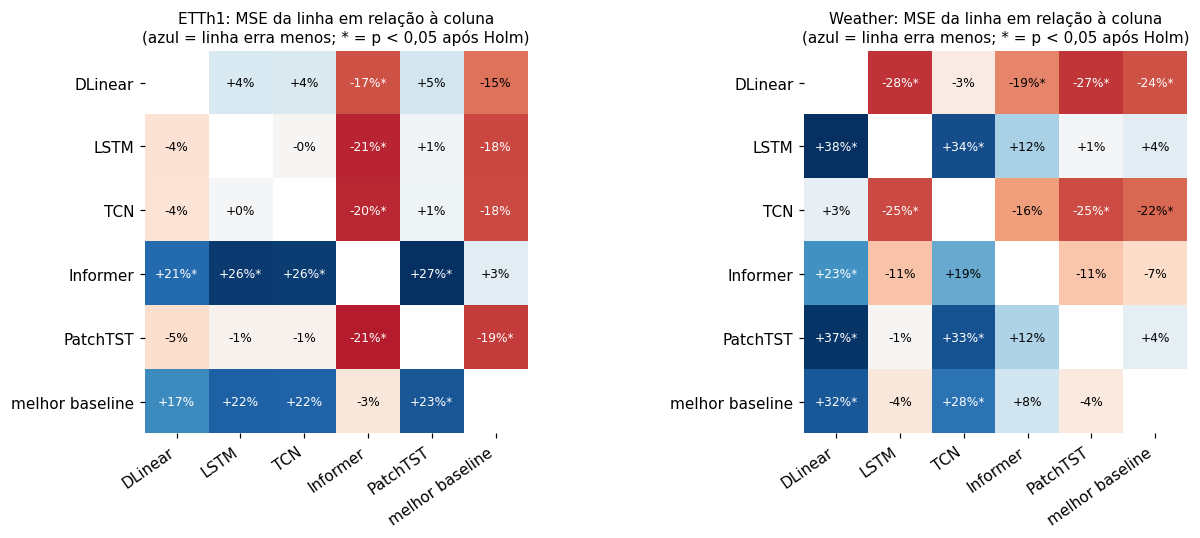

In [11]:
fig, axs = plt.subplots(1, len(BASES), figsize=(6.2 * len(BASES), 5), squeeze=False)
for ax, ds in zip(axs[0], BASES):
    d = DM[DM.base == ds]
    nomes = list(dict.fromkeys(list(d.A) + list(d.B)))
    M = pd.DataFrame(np.nan, index=nomes, columns=nomes); S = pd.DataFrame('', index=nomes, columns=nomes)
    for r in d.to_dict('records'):
        M.loc[r['A'], r['B']] = r['MSE A'] / r['MSE B'] - 1      # quanto a linha erra a mais (+) ou a menos (−)
        M.loc[r['B'], r['A']] = r['MSE B'] / r['MSE A'] - 1
        S.loc[r['A'], r['B']] = S.loc[r['B'], r['A']] = '*' if r['p (Holm)'] < .05 else ''
    lim = np.nanmax(np.abs(M.values))
    im = ax.imshow(M.values, cmap='RdBu', norm=TwoSlopeNorm(0, vmin=-lim, vmax=lim))
    for i in range(len(nomes)):
        for j in range(len(nomes)):
            if i != j:
                ax.text(j, i, f'{M.iloc[i, j]:+.0%}{S.iloc[i, j]}', ha='center', va='center', fontsize=8,
                        color='white' if abs(M.iloc[i, j]) > .6 * lim else 'black')
    ax.set_xticks(range(len(nomes)), nomes, rotation=35, ha='right'); ax.set_yticks(range(len(nomes)), nomes)
    ax.spines[:].set_visible(False)
    ax.set_title(f'{ds}: MSE da linha em relação à coluna\n(azul = linha erra menos; * = p < 0,05 após Holm)', fontsize=10)
plt.tight_layout(); salvar('fig6_diebold_mariano.png'); plt.show()

## 7. Custo computacional

Número de parâmetros e tempo médio de treino por execução, na janela escolhida. Na figura, a área de cada ponto é proporcional ao tempo de treino. O tempo depende do hardware: a maioria das execuções rodou em GPU T4 no Colab, e as que rodaram em CPU aparecem indicadas.

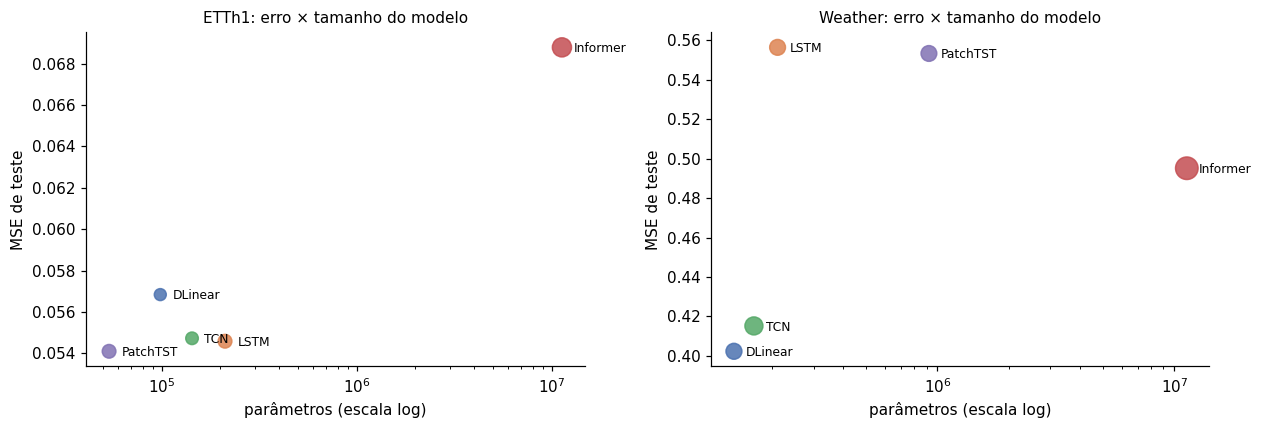

In [12]:
custo = (redes.merge(ESCOLHA['L'].rename('L_escolhida').reset_index(), on=['dataset', 'modelo'])
         .query('L == L_escolhida')
         .groupby(['dataset', 'modelo'])
         .agg(parametros=('n_parametros', 'first'), tempo_s=('tempo_treino_s', 'mean'), epocas=('epocas_rodadas', 'mean'),
              dispositivo=('dispositivo', lambda s: '/'.join(sorted(set(map(str, s)))))))
fig, axs = plt.subplots(1, len(BASES), figsize=(5.8 * len(BASES), 4), squeeze=False)
for ax, ds in zip(axs[0], BASES):
    c = custo.loc[ds].reindex(ORDEM).dropna(subset=['parametros'])
    mse = ESCOLHA.loc[ds].reindex(c.index)['mse']
    ax.scatter(c.parametros, mse, s=40 + 6 * np.sqrt(c.tempo_s), color=[CORES[m] for m in c.index], alpha=.85)
    for mod, r in c.iterrows():
        ax.annotate(mod, (r.parametros, mse[mod]), textcoords='offset points', xytext=(8, -3), fontsize=8)
    ax.set_xscale('log'); ax.set_xlabel('parâmetros (escala log)'); ax.set_ylabel('MSE de teste')
    ax.set_title(f'{ds}: erro × tamanho do modelo', fontsize=10)
plt.tight_layout(); salvar('fig7_custo.png'); plt.show()
custo['tempo por execução (min)'] = custo.pop('tempo_s') / 60
custo.style.format({'parametros': '{:,.0f}', 'tempo por execução (min)': '{:.1f}', 'epocas': '{:.1f}'})

## 8. Exemplo de previsão

Uma amostra fixa por base: o alvo do **meio do período de teste**, escolhido pela posição e não pelo resultado. Cada modelo usa a seed 0 e a janela escolhida pela validação. Os pesos vêm de `checkpoints/`, e a arquitetura vem da célula do modelo no notebook correspondente.

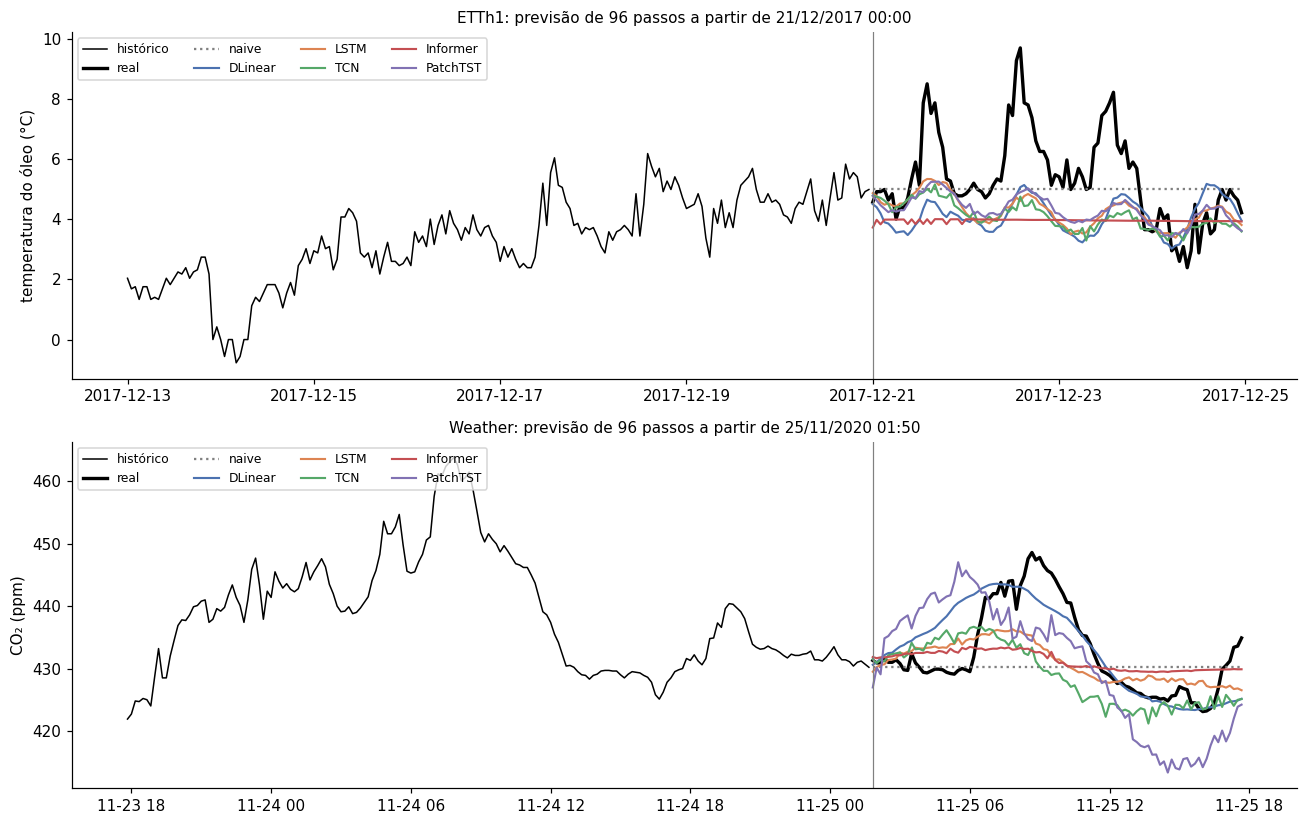

In [13]:
NOTEBOOK = {'DLinear': '10_dlinear', 'LSTM': '11_lstm', 'TCN': '12_tcn', 'Informer': '13_informer', 'PatchTST': '14_patchtst'}

def fabrica(mod, ds):
    """Executa a célula que define o modelo no notebook dele e devolve criar(L, H)."""
    candidatos = sorted(glob.glob(os.path.join(PROJETO, NOTEBOOK[mod] + '*.ipynb')), key=os.path.getmtime, reverse=True)
    with open(candidatos[0], encoding='utf-8') as f:
        nb = json.load(f)
    for c in nb['cells']:
        src = ''.join(c['source']) if isinstance(c['source'], list) else c['source']
        if c['cell_type'] == 'code' and 'def criar' in src:
            ns = {}
            with contextlib.redirect_stdout(io.StringIO()):
                exec(src, ns)
            return ns.get(f'criar_{ds.lower()}', ns['criar'])
    raise ValueError(f'célula do modelo não encontrada em {NOTEBOOK[mod]}')

def prever_exemplo(mod, ds, base, t):
    L = int(ESCOLHA.loc[(ds, mod), 'L'])
    lr = redes[(redes.dataset == ds) & (redes.modelo == mod)].lr.iloc[0]
    pesos = os.path.join(PROJETO, 'checkpoints', ds, mod, ru.id_execucao(ds, mod, L, lr, 0) + '.pt')
    modelo = ru.ComRevIN(fabrica(mod, ds)(L, ru.HORIZONTE)).to(ru.DISPOSITIVO)
    modelo.load_state_dict(torch.load(pesos, map_location=ru.DISPOSITIVO))
    torch.manual_seed(0)
    return ru.prever(modelo, base, np.array([t]), L)[0, :, 0].cpu().numpy()

H = ru.HORIZONTE
fig, axs = plt.subplots(len(BASES), 1, figsize=(12, 3.8 * len(BASES)), squeeze=False)
for ax, ds in zip(axs[:, 0], BASES):
    base = ru.carregar_base(ds)
    escala = lambda v: np.asarray(v) * base.meta['desvio_treino'] + base.meta['media_treino']
    te = base.indices_alvo('teste')
    t = int(te[len(te) // 2])
    passado, futuro = np.arange(t - 2 * H, t), np.arange(t, t + H)
    ax.plot(base.datas[passado], escala(base.y[passado]), color='black', lw=1, label='histórico')
    ax.plot(base.datas[futuro], escala(base.y[futuro]), color='black', lw=2.2, label='real')
    ax.plot(base.datas[futuro], escala(np.repeat(base.y[t - 1], H)), color='gray', ls=':', lw=1.5, label='naive')
    for mod in ORDEM:
        try:
            ax.plot(base.datas[futuro], escala(prever_exemplo(mod, ds, base, t)), color=CORES[mod], lw=1.4, label=mod)
        except Exception as erro:
            print(f'{ds} / {mod}: previsão de exemplo indisponível ({type(erro).__name__}: {erro})')
    ax.axvline(base.datas[t], color='gray', lw=.8)
    ax.set_ylabel(UNIDADE[ds])
    ax.set_title(f'{ds}: previsão de {H} passos a partir de {base.datas[t]:%d/%m/%Y %H:%M}', fontsize=10)
    ax.legend(fontsize=8, ncol=4, loc='upper left')
plt.tight_layout(); salvar('fig8_exemplo_previsao.png'); plt.show()

## 9. Tabela completa (apêndice)

Uma linha por execução, com o learning rate escolhido. Também é salva em `figuras/tabela_completa.csv`.

In [14]:
cols = ['dataset', 'modelo', 'L', 'seed', 'lr', 'mse_val', 'original_mse', 'original_mae', 'original_mse_ss'] + \
       [f'{p}_razao' for p in PERT] + ['melhor_epoca', 'epocas_rodadas', 'tempo_treino_s', 'dispositivo']
completo = (df[[c for c in cols if c in df.columns]]
            .sort_values(['dataset', 'modelo', 'L', 'seed'], na_position='first').reset_index(drop=True))
completo[['L', 'seed']] = completo[['L', 'seed']].astype('Int64')
completo.to_csv(os.path.join(FIG, 'tabela_completa.csv'), index=False)
completo.round(4)

,dataset,modelo,L,seed,lr,mse_val,original_mse,original_mae,original_mse_ss,embaralhar_tudo_razao,embaralhar_antigo_razao,embaralhar_recente_razao,embaralhar_blocos_razao,melhor_epoca,epocas_rodadas,tempo_treino_s,dispositivo
0,ETTh1,DLinear,96,0,0.001,0.0989,0.0553,0.1781,0.0547,1.2877,1.0323,1.1018,1.3906,3.0,8.0,3.1532,cpu
1,ETTh1,DLinear,96,1,0.001,0.0991,0.0554,0.1782,0.0549,1.3237,1.0348,1.1155,1.3964,8.0,13.0,6.5156,cpu
2,ETTh1,DLinear,96,2,0.001,0.0991,0.0549,0.1775,0.0543,1.3385,1.0414,1.1233,1.3951,12.0,17.0,6.5804,cpu
3,ETTh1,DLinear,192,0,0.001,0.0919,0.0550,0.1782,0.0561,1.4427,1.0440,1.1972,1.5373,8.0,13.0,9.0238,cpu
4,ETTh1,DLinear,192,1,0.001,0.0918,0.0551,0.1783,0.0564,1.4200,1.0383,1.1849,1.5271,5.0,10.0,7.0674,cpu
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,Weather,naive,336,<NA>,NaN,NaN,0.5550,0.5246,0.5550,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
140,Weather,naive,720,<NA>,NaN,NaN,0.5550,0.5246,0.5550,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
141,Weather,sazonal,96,<NA>,NaN,NaN,0.7282,0.6091,0.7282,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
142,Weather,sazonal,336,<NA>,NaN,NaN,0.7282,0.6091,0.7282,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None
